# Analyse exploratoire des données — Réussite académique des étudiants

**Projet :** Prédiction de l'abandon et de la réussite académique  
**Étape :** 02 — Exploratory Data Analysis (EDA)  
**Source :** `data.csv`

---

## 1. Objectifs de l'analyse

Cette étape permet de mieux comprendre la structure et la qualité du jeu de données avant la préparation des variables et la modélisation.

Les objectifs sont de :

- examiner la structure générale du jeu de données ;
- vérifier la présence de valeurs manquantes et de doublons ;
- décrire les principales variables ;
- repérer les valeurs potentiellement atypiques ;
- étudier la répartition de la variable cible `Target` ;
- explorer quelques relations entre les caractéristiques des étudiants et leur statut académique.

> **Périmètre :** cette analyse est exploratoire. Elle ne modifie pas les données et ne supprime aucune observation.

## 2. Configuration de l'environnement

Importation des bibliothèques et définition d'un thème graphique homogène pour faciliter la lecture des résultats.

In [5]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Paramètres d'affichage
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Thème graphique
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titleweight": "bold"
})

## 3. Chargement des données

Le fichier est chargé avec le séparateur `;`, conformément au format du jeu de données. Les espaces superflus dans les noms de colonnes sont retirés.

In [6]:
file_path = "/content/data.csv"

try:
    df = pd.read_csv(file_path, sep=";")
    df.columns = df.columns.str.strip()
    print("Chargement effectué avec succès.")
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"Fichier introuvable : {file_path}. "
        "Vérifiez que data.csv est bien présent dans l'environnement Colab."
    ) from error

print(f"Nombre d'observations : {df.shape[0]:,}")
print(f"Nombre de variables   : {df.shape[1]:,}")
display(df.head())

Chargement effectué avec succès.
Nombre d'observations : 4,424
Nombre de variables   : 37


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.00,1,19,12,5,9,127.30,1,0,0,1,1,0,20,0,0,0,0,0,0.00,0,0,0,0,0,0.00,0,10.80,1.40,1.74,Dropout
1,1,15,1,9254,1,1,160.00,1,1,3,3,3,142.50,1,0,0,0,1,0,19,0,0,6,6,6,14.00,0,0,6,6,6,13.67,0,13.90,-0.30,0.79,Graduate
2,1,1,5,9070,1,1,122.00,1,37,37,9,9,124.80,1,0,0,0,1,0,19,0,0,6,0,0,0.00,0,0,6,0,0,0.00,0,10.80,1.40,1.74,Dropout
3,1,17,2,9773,1,1,122.00,1,38,37,5,3,119.60,1,0,0,1,0,0,20,0,0,6,8,6,13.43,0,0,6,10,5,12.40,0,9.40,-0.80,-3.12,Graduate
4,2,39,1,8014,0,1,100.00,1,37,38,9,9,141.50,0,0,0,1,0,0,45,0,0,6,9,5,12.33,0,0,6,6,6,13.00,0,13.90,-0.30,0.79,Graduate


## 4. Vue d'ensemble du jeu de données

Cette section présente les dimensions du dataset, les types de variables et le nombre de valeurs renseignées.

In [7]:
overview = pd.DataFrame({
    "Type de données": df.dtypes.astype(str),
    "Valeurs non nulles": df.notna().sum(),
    "Valeurs manquantes": df.isna().sum(),
    "Taux de complétude (%)": (df.notna().mean() * 100).round(2),
    "Valeurs distinctes": df.nunique(dropna=True)
})

display(overview)

,Type de données,Valeurs non nulles,Valeurs manquantes,Taux de complétude (%),Valeurs distinctes
Marital status,int64,4424,0,100.00,6
Application mode,int64,4424,0,100.00,18
Application order,int64,4424,0,100.00,8
Course,int64,4424,0,100.00,17
Daytime/evening attendance,int64,4424,0,100.00,2
Previous qualification,int64,4424,0,100.00,17
Previous qualification (grade),float64,4424,0,100.00,101
Nacionality,int64,4424,0,100.00,21
Mother's qualification,int64,4424,0,100.00,29
Father's qualification,int64,4424,0,100.00,34


#### INTERPRETATION
Cette section présente la structure générale du dataset à travers les différentes variables, leurs types de données, leur niveau de complétude et le nombre de valeurs distinctes.

L'analyse montre que le jeu de données contient **4 424 observations**, réparties sur 36 variables explicatives et une variable cible (*Target*).

Toutes les variables disposent de 4 424 valeurs renseignées, soit un taux de complétude de **100 %**. Aucune valeur manquante n'a donc été détectée dans le dataset.

Les variables sont principalement de type `int64`, `float64` et `object`. Certaines variables numériques représentent des catégories codifiées, comme le statut matrimonial, le mode de candidature ou le niveau de qualification. Elles ne doivent donc pas nécessairement être interprétées comme des valeurs quantitatives.

Enfin, la variable cible (*Target*) contient trois catégories distinctes, correspondant aux trois situations académiques étudiées : diplômé (*Graduate*), étudiant toujours inscrit (*Enrolled*) et abandon (*Dropout*).


## 5. Qualité et intégrité des données

### 5.1 Valeurs manquantes

Le tableau ci-dessous permet d'identifier les variables qui contiennent des valeurs manquantes et de mesurer leur importance.

In [8]:
missing_report = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "Pourcentage (%)": (df.isna().mean() * 100).round(2)
})

missing_report = missing_report[missing_report["Valeurs manquantes"] > 0]
if missing_report.empty:
    print("Aucune valeur manquante détectée.")
else:
    display(missing_report.sort_values("Pourcentage (%)", ascending=False))

print(f"Total des valeurs manquantes : {df.isna().sum().sum():,}")

Aucune valeur manquante détectée.
Total des valeurs manquantes : 0


### Interprétation

Cette étape consiste à vérifier la présence de valeurs manquantes dans les différentes variables du jeu de données et à évaluer leur importance.

L'analyse révèle qu'aucune valeur manquante n'est présente dans le dataset. Les 4 424 observations sont entièrement renseignées pour l'ensemble des 37 variables.

**Résultat :** 0 valeur manquante détectée, soit un taux de complétude de 100 %.


### 5.2 Doublons

Un doublon correspond ici à une ligne entièrement identique. Cette vérification ne signifie pas qu'une ligne répétée est nécessairement une erreur métier : les résultats doivent être interprétés selon le contexte des données.

In [9]:
duplicate_count = df.duplicated().sum()
duplicate_rate = duplicate_count / len(df) * 100 if len(df) else 0

print(f"Lignes entièrement dupliquées : {duplicate_count:,}")
print(f"Part des doublons             : {duplicate_rate:.2f} %")

Lignes entièrement dupliquées : 0
Part des doublons             : 0.00 %


### Intrepretation

L'analyse ne révèle aucun doublon sur les 4 424 observations du dataset. Cela signifie qu'aucune ligne entièrement identique n'a été détectée.

Résultat :

Lignes entièrement dupliquées : 0.
Part des doublons : 0,00 %.

Cette absence de doublons constitue un premier indicateur positif de la qualité des données. Toutefois, elle ne garantit pas l'absence de répétitions ou d'incohérences au niveau de certaines variables individuelles.

### 5.3 Statistiques descriptives

Les statistiques descriptives donnent une première idée de la distribution des variables numériques et des modalités des variables catégorielles.

In [10]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Marital status,"4,424.00",NaN,NaN,NaN,1.18,0.61,1.00,1.00,1.00,1.00,6.00
Application mode,"4,424.00",NaN,NaN,NaN,18.67,17.48,1.00,1.00,17.00,39.00,57.00
Application order,"4,424.00",NaN,NaN,NaN,1.73,1.31,0.00,1.00,1.00,2.00,9.00
Course,"4,424.00",NaN,NaN,NaN,"8,856.64","2,063.57",33.00,"9,085.00","9,238.00","9,556.00","9,991.00"
Daytime/evening attendance,"4,424.00",NaN,NaN,NaN,0.89,0.31,0.00,1.00,1.00,1.00,1.00
Previous qualification,"4,424.00",NaN,NaN,NaN,4.58,10.22,1.00,1.00,1.00,1.00,43.00
Previous qualification (grade),"4,424.00",NaN,NaN,NaN,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Nacionality,"4,424.00",NaN,NaN,NaN,1.87,6.91,1.00,1.00,1.00,1.00,109.00
Mother's qualification,"4,424.00",NaN,NaN,NaN,19.56,15.60,1.00,2.00,19.00,37.00,44.00
Father's qualification,"4,424.00",NaN,NaN,NaN,22.28,15.34,1.00,3.00,19.00,37.00,44.00


### Interprétation

Les statistiques descriptives permettent d'obtenir une première compréhension de la distribution des variables numériques et de la répartition des modalités des variables catégorielles.

L'analyse montre que les 4 424 observations sont renseignées pour l'ensemble des variables.

Plusieurs constats peuvent être relevés :

* **Caractéristiques des étudiants :** l'âge moyen à l'inscription est d'environ 23 ans, avec des valeurs comprises entre 17 et 70 ans.
* **Résultats académiques :** les notes moyennes du premier et du deuxième semestre sont respectivement de 10,64 et 10,23. Ces résultats permettent d'avoir un premier aperçu des performances académiques des étudiants.
* **Unités curriculaires :** les étudiants ont en moyenne 6,27 unités curriculaires inscrites au premier semestre et 6,23 au deuxième semestre.
* **Situation économique :** les indicateurs économiques, notamment le taux de chômage, le taux d'inflation et le PIB, présentent des valeurs variables selon les observations.
* **Variable cible (Target) :** les trois catégories sont représentées dans le dataset. La catégorie *Graduate* est la plus fréquente, avec 2 209 observations.

Il convient toutefois de préciser que certaines variables de type numérique représentent en réalité des catégories codifiées. Leurs moyennes et leurs écarts-types ne possèdent donc pas toujours une interprétation statistique pertinente.

**Conclusion :** cette première analyse permet de mieux comprendre les caractéristiques des étudiants, leurs performances académiques et leur environnement socio-économique. Elle constitue une base pour les analyses exploratoires plus approfondies.


## 6. Analyse des valeurs potentiellement atypiques

La méthode de l'écart interquartile (IQR) est utilisée pour repérer les observations situées en dehors des bornes statistiques :

- borne inférieure : Q1 − 1,5 × IQR ;
- borne supérieure : Q3 + 1,5 × IQR.

**Important :** une valeur détectée comme atypique n'est pas automatiquement une erreur. Elle doit être étudiée selon le sens de la variable et le contexte métier. Aucune valeur n'est supprimée dans cette étape.

In [11]:
candidate_features = [
    "Age at enrollment",
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

numeric_features = [
    col for col in candidate_features
    if col in df.columns and pd.api.types.is_numeric_dtype(df[col])
]

outlier_rows = []

for col in numeric_features:
    values = df[col].dropna()
    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((values < lower) | (values > upper)).sum()

    outlier_rows.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Borne inférieure": lower,
        "Borne supérieure": upper,
        "Nombre détecté": int(count),
        "Pourcentage (%)": count / len(values) * 100
    })

outlier_report = pd.DataFrame(outlier_rows)

if outlier_report.empty:
    print("Aucune variable numérique candidate disponible pour cette analyse.")
else:
    display(outlier_report.round(2))

,Variable,Q1,Q3,IQR,Borne inférieure,Borne supérieure,Nombre détecté,Pourcentage (%)
0,Age at enrollment,19.00,25.00,6.00,10.00,34.00,441,9.97
1,Previous qualification (grade),125.00,140.00,15.00,102.50,162.50,179,4.05
2,Admission grade,117.90,134.80,16.90,92.55,160.15,86,1.94
3,Curricular units 1st sem (grade),11.00,13.40,2.40,7.40,17.00,726,16.41
4,Curricular units 2nd sem (grade),10.75,13.33,2.58,6.87,17.21,877,19.82


### Interpretation

La méthode de l'écart interquartile (IQR) a été utilisée pour identifier les observations présentant des valeurs statistiquement éloignées de la distribution habituelle des variables numériques.

L'analyse met en évidence plusieurs observations atypiques :

* **Age at enrollment :** 441 observations (9,97 %) sont identifiées comme atypiques. Ces valeurs correspondent notamment à des étudiants dont l'âge est relativement élevé par rapport à la majorité de la population étudiée.
* **Previous qualification (grade) :** 179 observations (4,05 %) sont détectées en dehors des bornes statistiques.
* **Admission grade :** 86 observations (1,94 %) présentent des valeurs atypiques. Cette variable contient relativement peu d'observations concernées.
* **Curricular units 1st sem (grade) :** 726 observations (16,41 %) sont identifiées comme atypiques.
* **Curricular units 2nd sem (grade) :** 877 observations (19,82 %) sont détectées comme atypiques. Il s'agit de la proportion la plus élevée parmi les variables analysées.

Les notes des deux semestres présentent donc une concentration importante de valeurs atypiques selon la méthode IQR. Cela peut notamment être lié à la présence de notes faibles, voire nulles, qui se situent en dessous des bornes inférieures calculées.

**Conclusion :** la détection des valeurs atypiques permet d'identifier les variables nécessitant une attention particulière lors de l'analyse exploratoire. Toutefois, ces observations ne sont pas nécessairement des erreurs. Elles peuvent représenter des situations réelles dans le parcours académique des étudiants.

Aucune observation n'a été supprimée ou modifiée à cette étape. Une analyse complémentaire sera nécessaire avant de décider d'un éventuel traitement.


### 6.1 Visualisation des distributions et des valeurs atypiques

Les boîtes à moustaches permettent de visualiser la dispersion des variables et les observations éloignées de la distribution centrale.

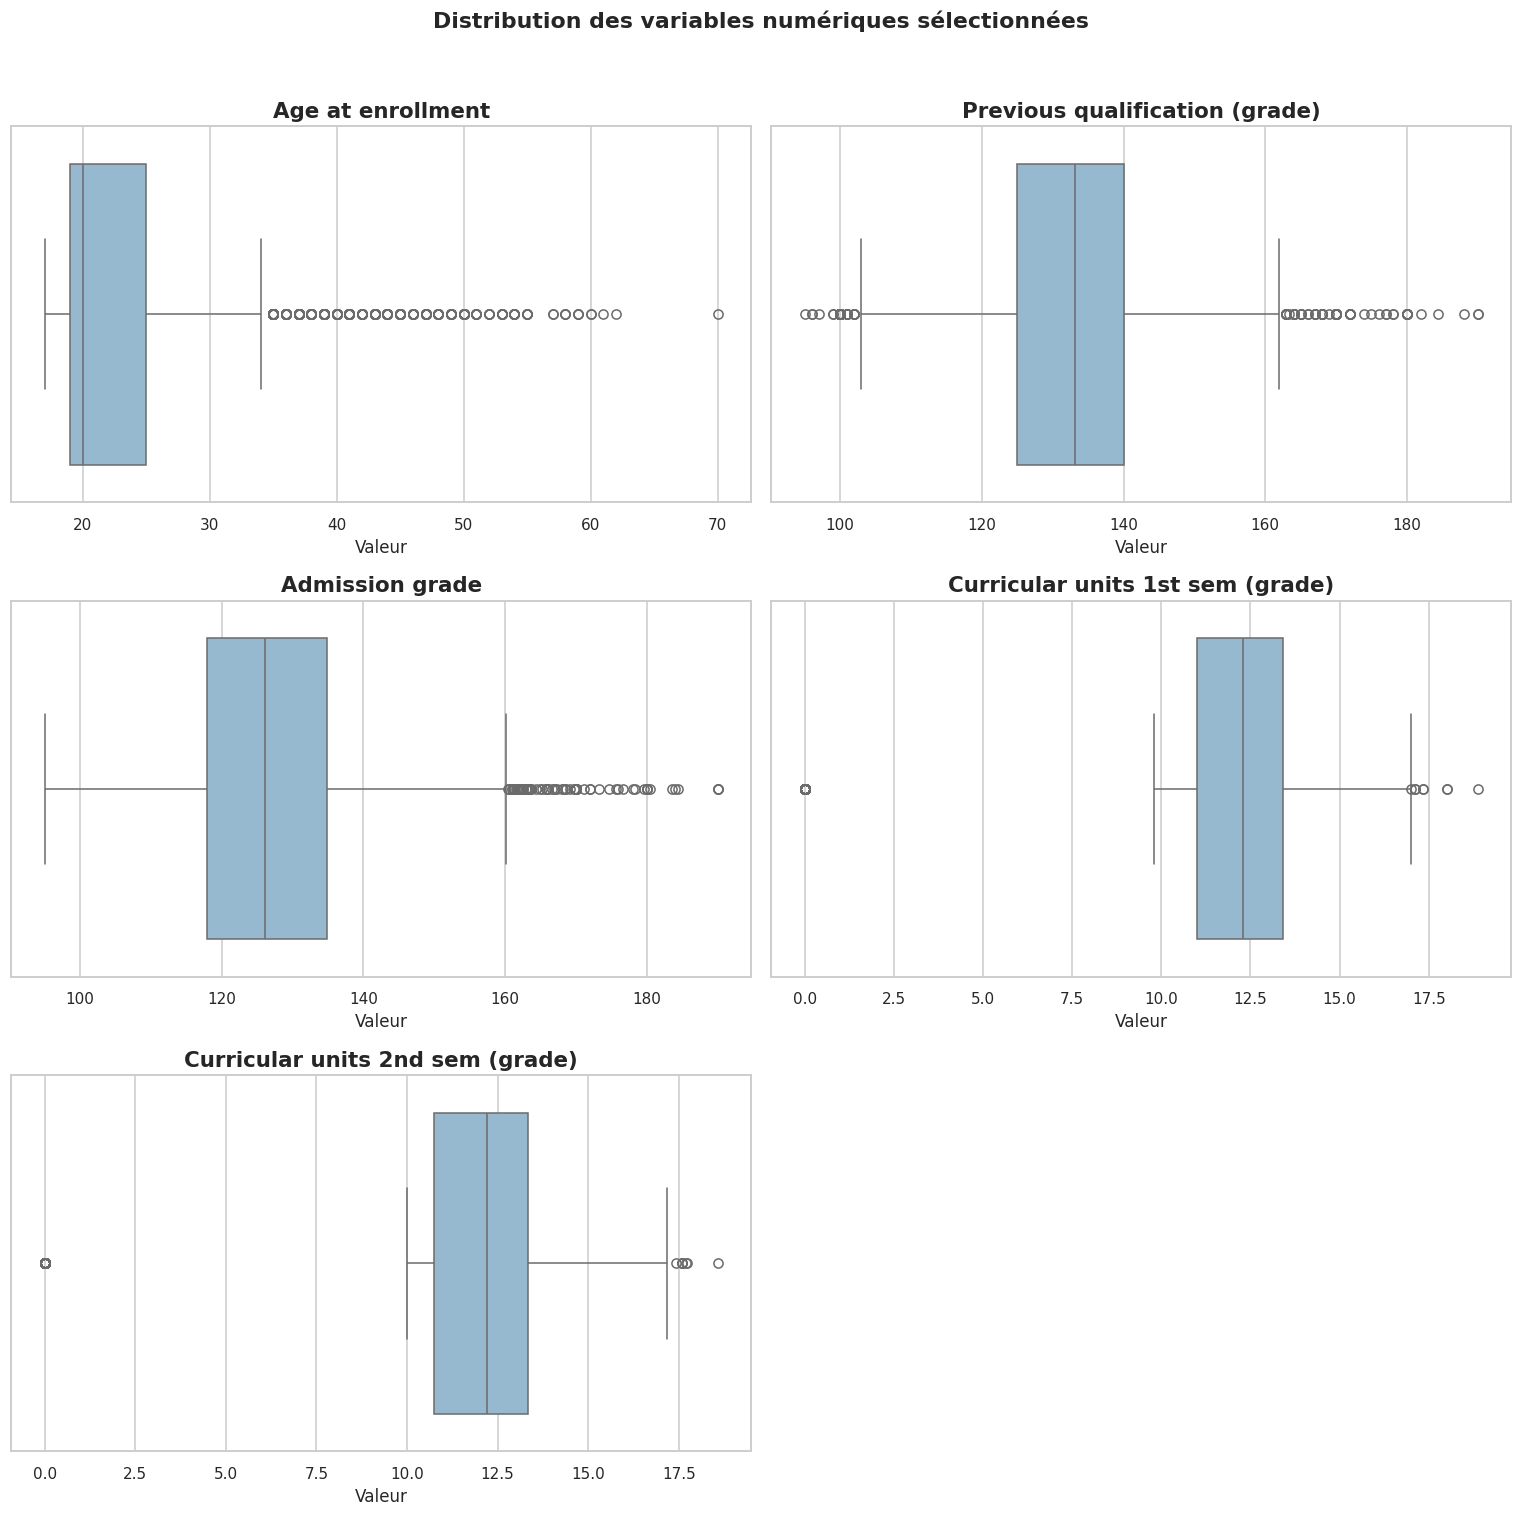

In [12]:
if numeric_features:
    n_cols = 2
    n_rows = int(np.ceil(len(numeric_features) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4.5 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, numeric_features):
        sns.boxplot(x=df[col], ax=ax, color="#8DBBD8")
        ax.set_title(col)
        ax.set_xlabel("Valeur")

    for ax in axes[len(numeric_features):]:
        ax.remove()

    fig.suptitle("Distribution des variables numériques sélectionnées", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune des variables numériques sélectionnées n'est disponible.")

## 7. Analyse de la variable cible

La variable `Target` représente le statut académique final des étudiants. Cette section examine la répartition des différentes catégories afin d'identifier un éventuel déséquilibre de classes.

,Effectif,Pourcentage (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


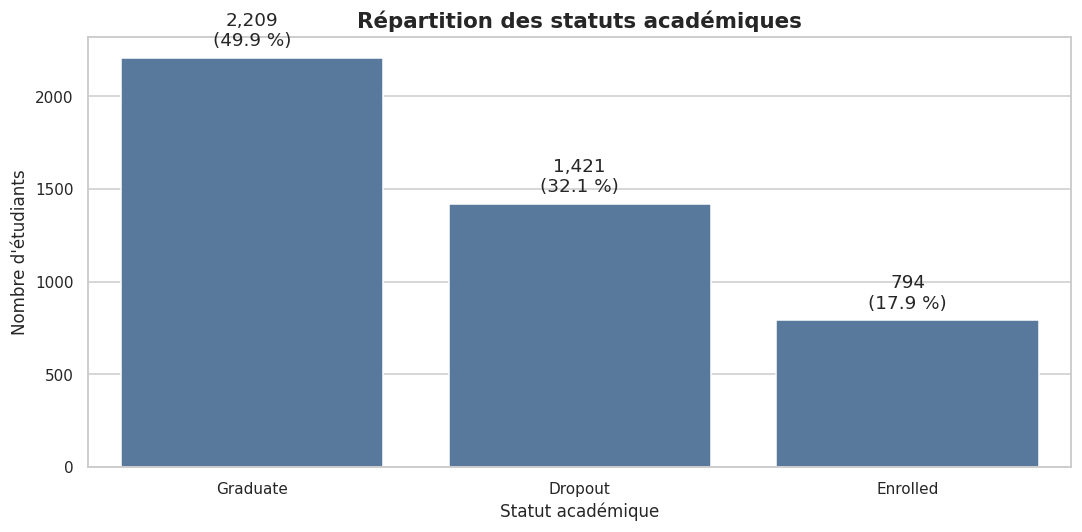

In [13]:
target_col = "Target"

if target_col not in df.columns:
    print("La variable cible 'Target' est absente du jeu de données.")
else:
    target_counts = df[target_col].value_counts(dropna=False)
    target_percentages = df[target_col].value_counts(normalize=True, dropna=False) * 100

    target_summary = pd.DataFrame({
        "Effectif": target_counts,
        "Pourcentage (%)": target_percentages.round(2)
    })
    display(target_summary)

    plt.figure(figsize=(10, 5))
    order = df[target_col].value_counts().index
    ax = sns.countplot(data=df, x=target_col, order=order, color="#4C78A8")

    total = len(df)
    for bar in ax.patches:
        height = bar.get_height()
        ax.annotate(
            f"{int(height):,}\n({height / total * 100:.1f} %)",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center", va="bottom",
            xytext=(0, 5), textcoords="offset points"
        )

    ax.set_title("Répartition des statuts académiques")
    ax.set_xlabel("Statut académique")
    ax.set_ylabel("Nombre d'étudiants")
    plt.tight_layout()
    plt.show()

## 8. Exploration de relations entre variables

### 8.1 Âge à l'inscription selon le statut académique

Cette comparaison permet d'observer comment l'âge à l'inscription se répartit dans les différentes catégories de `Target`. Elle met en évidence des associations descriptives, sans démontrer de relation causale.

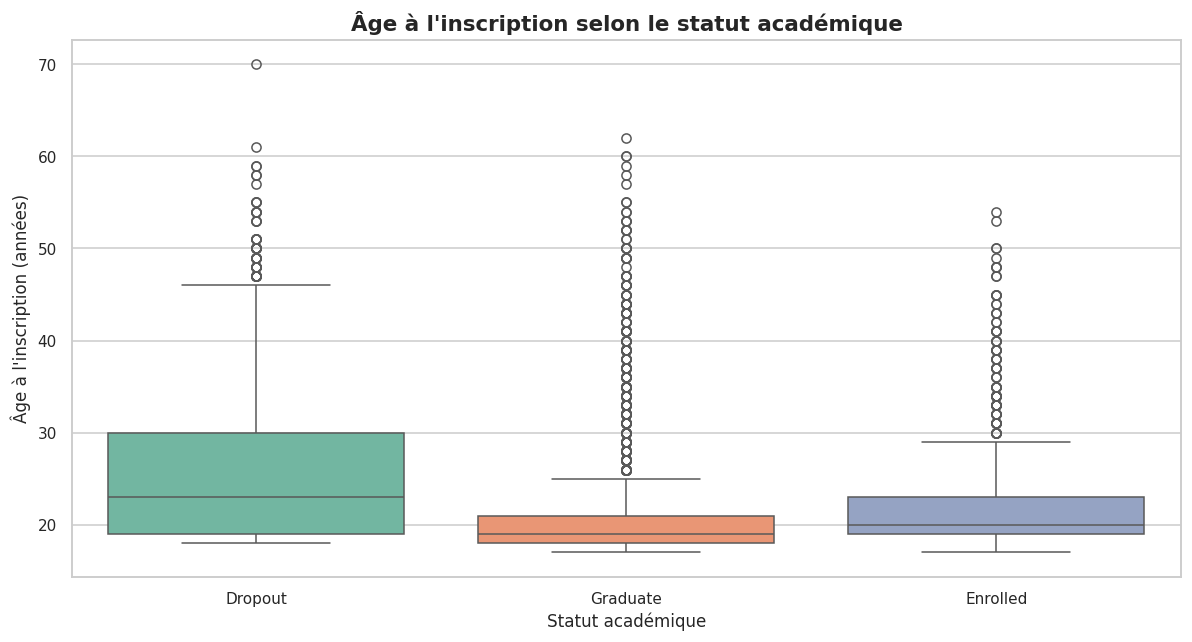

In [14]:
if {"Target", "Age at enrollment"}.issubset(df.columns):
    plt.figure(figsize=(11, 6))
    sns.boxplot(
        data=df,
        x="Target",
        y="Age at enrollment",
        hue="Target",
        legend=False,
        palette="Set2"
    )
    plt.title("Âge à l'inscription selon le statut académique")
    plt.xlabel("Statut académique")
    plt.ylabel("Âge à l'inscription (années)")
    plt.tight_layout()
    plt.show()
else:
    print("Les colonnes 'Target' et/ou 'Age at enrollment' sont absentes.")

### 8.2 Résultats académiques des deux premiers semestres

Les notes des unités curriculaires des deux premiers semestres sont comparées selon le statut final. Cette vue peut aider à repérer des différences descriptives entre les groupes.

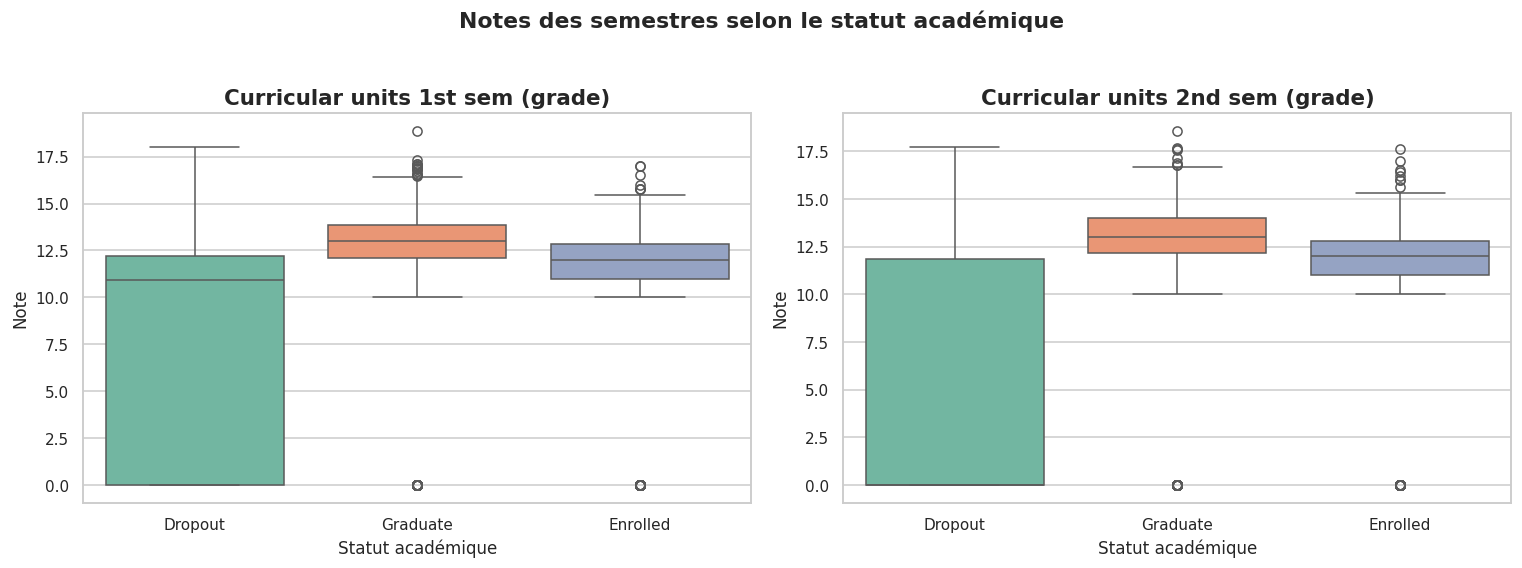

In [15]:
grade_columns = [
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]
available_grades = [col for col in grade_columns if col in df.columns]

if "Target" in df.columns and available_grades:
    fig, axes = plt.subplots(1, len(available_grades), figsize=(7 * len(available_grades), 5))
    if len(available_grades) == 1:
        axes = [axes]

    for ax, col in zip(axes, available_grades):
        sns.boxplot(
            data=df,
            x="Target",
            y=col,
            hue="Target",
            legend=False,
            ax=ax,
            palette="Set2"
        )
        ax.set_title(col)
        ax.set_xlabel("Statut académique")
        ax.set_ylabel("Note")

    fig.suptitle("Notes des semestres selon le statut académique", y=1.03)
    plt.tight_layout()
    plt.show()
else:
    print("Les colonnes nécessaires à cette comparaison ne sont pas disponibles.")

## 9. Synthèse de l'analyse exploratoire

À la fin de cette étape, les éléments suivants doivent être documentés à partir des résultats réellement obtenus :

1. **Structure :** nombre d'observations, nombre de variables et types de données.
2. **Complétude :** présence ou absence de valeurs manquantes et variables concernées.
3. **Doublons :** nombre de lignes entièrement dupliquées.
4. **Valeurs atypiques :** variables concernées et importance des observations détectées par la méthode IQR.
5. **Variable cible :** effectifs et proportions des catégories de `Target`.
6. **Relations explorées :** différences descriptives observées pour l'âge et les notes semestrielles.

### Conclusion

Cette analyse fournit une première compréhension du jeu de données et permet d'identifier les points à traiter lors de la prochaine étape. Les décisions de nettoyage, d'encodage et de transformation des variables seront prises dans le notebook dédié à la préparation des données.

> **Étape suivante :** préparation et transformation des données (Data Cleaning & Feature Engineering).